# Build Your First Neural Network
## Banknote authentication with a Keras ANN

**Problem statement:** Build Your First Neural Network — Build a small ANN in Keras with this exact architecture: Dense(16, activation="relu") → Dense(8, activation="relu") → Dense(1, activation="sigmoid"). Compile it with the Adam optimizer and binary_crossentropy loss, split the data into train/test, train for about 30 epochs, and report test accuracy. Plot the training vs. validation loss curve. In 2–3 sentences, explain in your own words what forward propagation and backpropagation are doing each epoch as the model trains.

**Dataset:** [Bank Note Authentication UCI data on Kaggle](https://www.kaggle.com/datasets/ritesaluja/bank-note-authentication-uci-data).

**Submission by:** Bhanupriyacn. This notebook contains the exact required
network, all 30 training epochs, held-out test accuracy, the training/validation
loss plot, and a three-sentence explanation of propagation.

## 1. Approach

We use the four numeric image-derived features (`variance`, `skewness`,
`curtosis`, and `entropy`) to predict the source's binary `class` label.
`curtosis` is the column spelling in this CSV. The sigmoid output represents
the model's probability of class 1; class 0 is the other source label.

Remove identical rows so copies cannot inflate hold-out performance. Reserve
20% of unique rows for testing, and reserve 20% of the remaining development
data for validation. Fit StandardScaler only on the actual training rows.
Train the requested ANN for exactly 30 epochs using Adam and binary
cross-entropy. Test rows remain separate from scaling, training and validation.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")

import io
import json
import platform
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print(f"Python {platform.python_version()} | TensorFlow {tf.__version__} | "
      f"Keras {keras.__version__} | scikit-learn {sklearn.__version__}")
print("Keras backend:", keras.backend.backend())

Python 3.12.14 | TensorFlow 2.20.0 | Keras 3.11.3 | scikit-learn 1.9.1
Keras backend: tensorflow


## 2. Load and inspect the data

On Kaggle, attach the linked dataset. The loader searches `/kaggle/input` for
`BankNote_Authentication.csv`. It also supports that file in a local
`data/banknote_authentication/` folder or beside the notebook. If the file is
missing, it can download the public Kaggle archive when internet is available.

In [2]:
cwd = Path.cwd()
candidates = []
if Path("/kaggle/input").exists():
    candidates.extend(sorted(Path("/kaggle/input").rglob("BankNote_Authentication.csv")))
for base in (cwd, cwd.parent):
    candidates.extend([base / "data" / "banknote_authentication" / "BankNote_Authentication.csv",
                       base / "data" / "BankNote_Authentication.csv",
                       base / "BankNote_Authentication.csv"])
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    url = ("https://www.kaggle.com/api/v1/datasets/download/"
           "ritesaluja/bank-note-authentication-uci-data")
    try:
        with urlopen(url, timeout=60) as response:
            archive_bytes = response.read()
        with ZipFile(io.BytesIO(archive_bytes)) as archive:
            member = next(name for name in archive.namelist()
                          if Path(name).name == "BankNote_Authentication.csv")
            folder = cwd / "data" / "banknote_authentication"
            folder.mkdir(parents=True, exist_ok=True)
            data_path = folder / "BankNote_Authentication.csv"
            data_path.write_bytes(archive.read(member))
    except Exception as exc:
        raise RuntimeError("Attach the banknote dataset on Kaggle or put "
                           "BankNote_Authentication.csv in data/banknote_authentication.") from exc

raw = pd.read_csv(data_path)
raw.columns = raw.columns.str.strip()
features = ["variance", "skewness", "curtosis", "entropy"]
assert set([*features, "class"]).issubset(raw.columns)
raw = raw[[*features, "class"]].apply(pd.to_numeric, errors="raise")
raw_rows = len(raw)
print(f"Loaded {data_path.name}: {raw_rows} rows, {len(features)} input features")
display(raw.head())
display(raw.isna().sum().rename("missing_values").to_frame())
display(raw[features].describe().round(3))
missing_rows_removed = int(raw.isna().any(axis=1).sum())
data = raw.dropna().copy()
duplicates_removed = int(data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
assert np.isfinite(data.to_numpy()).all()
assert set(data["class"]) == {0, 1}
assert data.groupby(features)["class"].nunique().max() == 1
print(f"Missing rows removed: {missing_rows_removed}; duplicates removed: {duplicates_removed}")
print(f"Rows retained: {len(data)}")
display(data["class"].value_counts().sort_index().rename("rows").to_frame())

Loaded BankNote_Authentication.csv: 1372 rows, 4 input features


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


,missing_values
variance,0
skewness,0
curtosis,0
entropy,0
class,0


,variance,skewness,curtosis,entropy
count,1372.000,1372.000,1372.000,1372.000
mean,0.434,1.922,1.398,-1.192
std,2.843,5.869,4.310,2.101
min,-7.042,-13.773,-5.286,-8.548
25%,-1.773,-1.708,-1.575,-2.413
50%,0.496,2.320,0.617,-0.587
75%,2.821,6.815,3.179,0.395
max,6.825,12.952,17.927,2.450


Missing rows removed: 0; duplicates removed: 24
Rows retained: 1348


,rows
class,
0,738
1,610


## 3. Train, validation and test split; feature scaling

Both splits are stratified by class and use `random_state=42`. Approximately
64% of the data is used for training, 16% for validation, and 20% for testing.
Validation loss is measured after each epoch; it does not update the weights.
The test set is evaluated after all 30 epochs, without selecting the best epoch
or tuning model settings on its results.

In [3]:
all_indices = np.arange(len(data))
development_indices, test_indices = train_test_split(
    all_indices, test_size=0.20, stratify=data["class"], random_state=RANDOM_STATE)
train_indices, val_indices = train_test_split(
    development_indices, test_size=0.20,
    stratify=data.iloc[development_indices]["class"], random_state=RANDOM_STATE)
assert set(train_indices).isdisjoint(val_indices)
assert set(train_indices).isdisjoint(test_indices)
assert set(val_indices).isdisjoint(test_indices)
assert len(train_indices) + len(val_indices) + len(test_indices) == len(data)

scaler = StandardScaler()
X_train = scaler.fit_transform(data.iloc[train_indices][features]).astype("float32")
X_val = scaler.transform(data.iloc[val_indices][features]).astype("float32")
X_test = scaler.transform(data.iloc[test_indices][features]).astype("float32")
y_train = data.iloc[train_indices]["class"].to_numpy(dtype="float32").reshape(-1, 1)
y_val = data.iloc[val_indices]["class"].to_numpy(dtype="float32").reshape(-1, 1)
y_test = data.iloc[test_indices]["class"].to_numpy(dtype="float32").reshape(-1, 1)
assert scaler.n_samples_seen_ == len(train_indices)
assert np.allclose(X_train.mean(axis=0), 0, atol=1e-6)
assert np.allclose(X_train.std(axis=0), 1, atol=1e-6)
split_rows = []
for name, indices in [("train", train_indices), ("validation", val_indices), ("test", test_indices)]:
    counts = data.iloc[indices]["class"].value_counts()
    split_rows.append({"partition": name, "rows": len(indices),
                       "class_0": int(counts.get(0, 0)), "class_1": int(counts.get(1, 0)),
                       "percentage": 100 * len(indices) / len(data)})
split_summary = pd.DataFrame(split_rows)
display(split_summary.round(2))
display(pd.DataFrame({"feature": features, "training_mean": scaler.mean_,
                      "training_std": scaler.scale_}).round(4))
print("Scaler fitted on training rows only; all three partitions are disjoint.")

,partition,rows,class_0,class_1,percentage
0,train,862,472,390,63.95
1,validation,216,118,98,16.02
2,test,270,148,122,20.03


,feature,training_mean,training_std
0,variance,0.4867,2.8981
1,skewness,1.7941,5.9756
2,curtosis,1.4566,4.4911
3,entropy,-1.1651,2.1073


Scaler fitted on training rows only; all three partitions are disjoint.


## 4. Exact required Keras architecture

`Dense(16, activation="relu") → Dense(8, activation="relu") → Dense(1, activation="sigmoid")`

The Input declaration supplies the four-feature shape; it adds no trainable
layer or parameters. The three Dense layers have **225 trainable parameters**
in total. Adam uses a learning rate of 0.001, and the loss is
`binary_crossentropy`, with binary accuracy as the evaluation metric.

In [4]:
keras.backend.clear_session()
keras.utils.set_random_seed(RANDOM_STATE)
model = keras.Sequential([
    keras.Input(shape=(len(features),), name="banknote_features"),
    keras.layers.Dense(16, activation="relu", name="hidden_16"),
    keras.layers.Dense(8, activation="relu", name="hidden_8"),
    keras.layers.Dense(1, activation="sigmoid", name="binary_output"),
], name="first_banknote_ann")
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy", metrics=["accuracy"])
assert len(model.layers) == 3
assert [layer.units for layer in model.layers] == [16, 8, 1]
assert [layer.activation.__name__ for layer in model.layers] == ["relu", "relu", "sigmoid"]
assert isinstance(model.optimizer, keras.optimizers.Adam)
assert model.loss == "binary_crossentropy"
assert model.count_params() == 225
model.summary()

Model: "first_banknote_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_16 (Dense)               │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_8 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary_output (Dense)           │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Train for 30 epochs

Use batches of 32, shuffle the training rows each epoch, and pass the separate
validation partition explicitly to `fit`. There is no early stopping, so the
network completes exactly 30 epochs. TensorFlow datasets below limit their
private thread pools for reliable CPU execution; they do not change the model
architecture or split.

In [5]:
BATCH_SIZE = 32
EPOCHS = 30
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(len(X_train), seed=RANDOM_STATE,
                            reshuffle_each_iteration=True).batch(BATCH_SIZE).with_options(options)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).with_options(options)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).with_options(options)

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2)
assert len(history.history["loss"]) == 30
assert len(history.history["val_loss"]) == 30
assert np.isfinite(history.history["loss"]).all()
assert np.isfinite(history.history["val_loss"]).all()
history_table = pd.DataFrame(history.history)
history_table.insert(0, "epoch", np.arange(1, EPOCHS + 1))
display(history_table.tail().round(4))

Epoch 1/30


27/27 - 0s - 16ms/step - accuracy: 0.8875 - loss: 0.5538 - val_accuracy: 0.8843 - val_loss: 0.5199


Epoch 2/30


27/27 - 0s - 454us/step - accuracy: 0.8875 - loss: 0.4809 - val_accuracy: 0.8889 - val_loss: 0.4556


Epoch 3/30


...

Epoch 29/30


27/27 - 0s - 449us/step - accuracy: 0.9954 - loss: 0.0147 - val_accuracy: 0.9907 - val_loss: 0.0233


Epoch 30/30


27/27 - 0s - 456us/step - accuracy: 0.9954 - loss: 0.0139 - val_accuracy: 0.9907 - val_loss: 0.0227


,epoch,accuracy,loss,val_accuracy,val_loss
25,26,0.9954,0.0178,0.9907,0.0261
26,27,0.9954,0.0166,0.9907,0.0252
27,28,0.9954,0.0159,0.9907,0.0244
28,29,0.9954,0.0147,0.9907,0.0233
29,30,0.9954,0.0139,0.9907,0.0227


## 6. Training vs. validation loss curve

The training curve summarizes binary cross-entropy on training batches, while
the validation curve measures loss on unseen validation rows after each epoch.
Sustained divergence, with training loss falling while validation loss rises,
would suggest overfitting. The test set is not used in either curve.

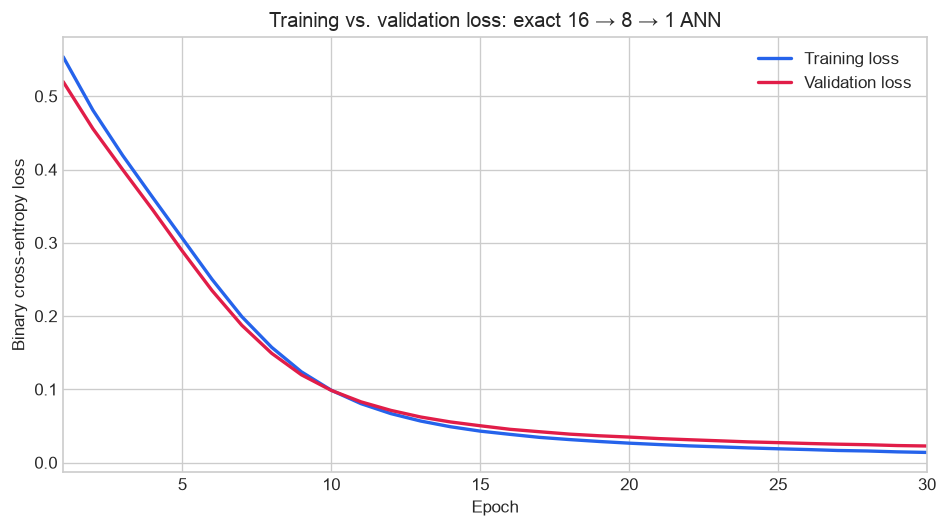

In [6]:
artifact_dir = (Path("/kaggle/working/banknote_ann_outputs")
                if Path("/kaggle/working").exists()
                else Path.cwd().parent / "outputs" / "banknote_ann_results")
artifact_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(history_table["epoch"], history_table["loss"], color="#2563eb", linewidth=2,
        label="Training loss")
ax.plot(history_table["epoch"], history_table["val_loss"], color="#e11d48", linewidth=2,
        label="Validation loss")
ax.set(xlabel="Epoch", ylabel="Binary cross-entropy loss",
       title="Training vs. validation loss: exact 16 → 8 → 1 ANN", xlim=(1, 30))
ax.legend()
fig.tight_layout()
fig.savefig(artifact_dir / "training_validation_loss.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Report test accuracy after training

Evaluate the final model from epoch 30 on the held-out test set. The sigmoid
probability is converted to class 1 when it exceeds 0.5, and class 0 otherwise.
The independent accuracy calculation checks Keras's reported test metric.

In [7]:
test_metrics = model.evaluate(test_ds, verbose=0, return_dict=True)
probabilities = model.predict(test_ds, verbose=0).reshape(-1)
predictions = (probabilities > 0.5).astype("int32")
true_labels = y_test.reshape(-1).astype("int32")
test_accuracy = accuracy_score(true_labels, predictions)
assert np.isclose(test_accuracy, test_metrics["accuracy"], atol=1e-6)
correct = int((predictions == true_labels).sum())
print(f"Test accuracy: {100 * test_accuracy:.2f}% ({correct}/{len(y_test)} correct)")
print(f"Test binary cross-entropy loss: {test_metrics['loss']:.4f}")
display(pd.DataFrame({"metric": ["test_accuracy", "test_loss", "test_rows"],
                      "value": [test_accuracy, test_metrics["loss"], len(y_test)]}))
display(pd.DataFrame(confusion_matrix(true_labels, predictions, labels=[0, 1]),
                     index=["True class 0", "True class 1"],
                     columns=["Predicted class 0", "Predicted class 1"]))

Test accuracy: 98.89% (267/270 correct)
Test binary cross-entropy loss: 0.0162


,metric,value
0,test_accuracy,0.988889
1,test_loss,0.016226
2,test_rows,270.000000


,Predicted class 0,Predicted class 1
True class 0,145,3
True class 1,0,122


## 8. Forward propagation and backpropagation (3 sentences)

During forward propagation, each training batch passes through the two ReLU layers and the sigmoid output to produce predictions, which are compared with the true labels using binary cross-entropy. Backpropagation carries the loss gradient backward through those layers so Adam can update each weight and bias after the batch. An epoch repeats these steps across the training set, then computes validation loss without updating the weights.

In [8]:
summary = {
    "dataset": "ritesaluja/bank-note-authentication-uci-data",
    "raw_rows": raw_rows, "duplicates_removed": duplicates_removed,
    "unique_rows": int(len(data)), "features": features,
    "train_rows": int(len(X_train)), "validation_rows": int(len(X_val)),
    "test_rows": int(len(X_test)), "random_state": RANDOM_STATE,
    "dense_units": [16, 8, 1], "activations": ["relu", "relu", "sigmoid"],
    "parameters": int(model.count_params()), "optimizer": "Adam",
    "learning_rate": 0.001, "loss": "binary_crossentropy", "epochs": EPOCHS,
    "batch_size": BATCH_SIZE, "correct_test_predictions": correct,
    "test_accuracy": float(test_accuracy), "test_loss": float(test_metrics["loss"]),
    "final_training_loss": float(history.history["loss"][-1]),
    "final_validation_loss": float(history.history["val_loss"][-1]),
    "tensorflow_version": tf.__version__, "keras_version": keras.__version__,
}
display(Markdown(f"""
## 9. Submission conclusion

The exact **16 → 8 → 1** network, with **ReLU → ReLU → sigmoid** activations,
was compiled with **Adam** and **binary_crossentropy** and trained for **30
epochs**. It achieved **{100 * test_accuracy:.2f}% test accuracy**
(**{correct}/{len(y_test)}** correct predictions) and a test loss of
**{test_metrics['loss']:.4f}**.

The analysis retained **{len(data)}** unique rows after removing
**{duplicates_removed}** duplicates. Its disjoint partitions contain
**{len(X_train)} training**, **{len(X_val)} validation** and **{len(X_test)} test**
rows; the scaler was fitted only on the training partition. The plot shows
training and validation losses for all 30 epochs, and the explanation above
describes the forward and backward passes in three sentences.

These are results from one fixed split of this dataset, not a guarantee of
accuracy on new banknotes. The seed and data split are fixed; neural-network
initialization and numerical operations can still vary across TensorFlow/Keras
versions or hardware. Library versions are printed for reproducibility.
"""))
history_table.to_csv(artifact_dir / "training_history.csv", index=False)
split_summary.to_csv(artifact_dir / "split_summary.csv", index=False)
pd.DataFrame({"unique_row": test_indices, "true_class": true_labels,
              "predicted_class": predictions, "class_1_probability": probabilities})    .to_csv(artifact_dir / "test_predictions.csv", index=False)
(artifact_dir / "results_summary.json").write_text(json.dumps(summary, indent=2))
(artifact_dir / "propagation_explanation.txt").write_text(
    "During forward propagation, each training batch passes through the two ReLU "
    "layers and the sigmoid output to produce predictions, which are compared "
    "with the true labels using binary cross-entropy. Backpropagation carries the "
    "loss gradient backward through those layers so Adam can update each weight "
    "and bias after the batch. An epoch repeats these steps across the training "
    "set, then computes validation loss without updating the weights.")
print("Exported training history, loss curve, split, test predictions and explanation.")


## 9. Submission conclusion

The exact **16 → 8 → 1** network, with **ReLU → ReLU → sigmoid** activations,
was compiled with **Adam** and **binary_crossentropy** and trained for **30
epochs**. It achieved **98.89% test accuracy**
(**267/270** correct predictions) and a test loss of
**0.0162**.

The analysis retained **1348** unique rows after removing
**24** duplicates. Its disjoint partitions contain
**862 training**, **216 validation** and **270 test**
rows; the scaler was fitted only on the training partition. The plot shows
training and validation losses for all 30 epochs, and the explanation above
describes the forward and backward passes in three sentences.

These are results from one fixed split of this dataset, not a guarantee of
accuracy on new banknotes. The seed and data split are fixed; neural-network
initialization and numerical operations can still vary across TensorFlow/Keras
versions or hardware. Library versions are printed for reproducibility.


Exported training history, loss curve, split, test predictions and explanation.


## References

- [Dataset on Kaggle](https://www.kaggle.com/datasets/ritesaluja/bank-note-authentication-uci-data).
- [Keras Dense layers](https://keras.io/api/layers/core_layers/dense/).
- [Keras compile, fit and evaluate](https://keras.io/api/models/model_training_apis/).
- [Adam optimizer](https://keras.io/api/optimizers/adam/).
- [Binary cross-entropy](https://keras.io/api/losses/probabilistic_losses/#binarycrossentropy-class).